# Diabetes Prediction System - Comprehensive Data Science Project
This notebook guides you through the complete end-to-end data science process to predict diabetes in patients based on their medical history and demographic details.

---

### Step 1: Problem Definition
Diabetes is a chronic medical condition that occurs when the pancreas does not produce enough insulin, or when the body cannot effectively use the insulin it produces. The problem is to predict whether a patient has diabetes based on several diagnostic measurements.


### Step 2: Define Objective
The primary objective is to build a reliable machine learning model that predicts the presence of diabetes (target variable `diabetes` = 1) or absence (target variable `diabetes` = 0) with high accuracy and high recall, which is crucial for early healthcare intervention.


### Step 3: Type of Data Science Problem
This is a **Supervised Learning** problem, specifically a **Binary Classification** problem, since the target variable `diabetes` has only two possible outcomes: 0 (No Diabetes) and 1 (Diabetes).


### Step 4: Data Collection
The dataset used is `diabetes_prediction_dataset.csv`. It contains medical records of 100,000 patients with features such as gender, age, hypertension, heart disease, smoking history, BMI, HbA1c level, blood glucose level, and the target label.


### Step 5: Dataset Loading
We will load the dataset using the `pandas` library.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')
print("Dataset loaded successfully!")


Dataset loaded successfully!


### Step 6: Understand Dataset
Let's look at the shape of the dataset and check the first 5 records.


In [2]:
# Print shape of the dataset
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# Display first 5 rows
df.head()


Number of rows: 100000
Number of columns: 9


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### Step 7: Check Column Names
Let's see what columns are available in our dataset.


In [3]:
# Print column names
print("Columns in the dataset:")
print(list(df.columns))


Columns in the dataset:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


### Step 8: Check Data Types
Let's inspect the data types of each column to understand their representations.


In [4]:
# Check data types of all columns
df.dtypes


gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

### Step 9: Find Missing Values
Checking for missing or null values in each column is essential to keep the dataset clean.


In [5]:
# Check for null values in each column
df.isnull().sum()


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

### Step 10: Handle Missing Values
Since there are no missing values in this dataset, we don't need to impute any values. If there were, we would fill them using mean/median for numerical columns and mode for categorical columns.


In [6]:
# Display message indicating no missing values
if df.isnull().sum().sum() == 0:
    print("No missing values found in the dataset. No handling required.")
else:
    # Example logic for handling missing values
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype == 'object':
                df[col].fillna(df[col].mode()[0], inplace=True)
            else:
                df[col].fillna(df[col].median(), inplace=True)
    print("Missing values handled successfully.")


No missing values found in the dataset. No handling required.


### Step 11: Find Duplicate Data
Let's check if there are duplicate records in the dataset.


In [7]:
# Find duplicate rows count
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 3854


### Step 12: Remove Duplicate Data
We will drop duplicate rows to prevent overfitting and data leakage.


In [8]:
# Remove duplicates in-place
df.drop_duplicates(inplace=True)
print(f"Dataset shape after removing duplicates: {df.shape}")


Dataset shape after removing duplicates: (96146, 9)


### Step 13: Check Incorrect Values
Let's inspect categorical columns for unexpected or incorrect values.


In [9]:
# Check unique values in categorical columns
print("Gender unique values:", df['gender'].unique())
print("Smoking history unique values:", df['smoking_history'].unique())


Gender unique values: ['Female' 'Male' 'Other']
Smoking history unique values: ['never' 'No Info' 'current' 'former' 'ever' 'not current']


### Step 14: Data Cleaning
We notice that `gender` has 'Other' which is extremely rare, and `smoking_history` has 'No Info' which represents missing information. Let's clean these by filtering out 'Other' gender to keep it binary and simple, and we can keep 'No Info' as a valid category.


In [10]:
# Filter out 'Other' from gender
df = df[df['gender'] != 'Other']
print(f"Dataset shape after filtering 'Other' gender: {df.shape}")
print("Gender unique values now:", df['gender'].unique())


Dataset shape after filtering 'Other' gender: (96128, 9)
Gender unique values now: ['Female' 'Male']


### Step 15: Data Manipulation
Let's create a new feature `bmi_category` based on BMI values to categorize patients.


In [11]:
# Create BMI categories
def categorize_bmi(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif 18.5 <= bmi < 25:
        return 'Normal'
    elif 25 <= bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['bmi_category'] = df['bmi'].apply(categorize_bmi)
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category
0,Female,80.0,0,1,never,25.19,6.6,140,0,Overweight
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,Overweight
2,Male,28.0,0,0,never,27.32,5.7,158,0,Overweight
3,Female,36.0,0,0,current,23.45,5.0,155,0,Normal
4,Male,76.0,1,1,current,20.14,4.8,155,0,Normal


### Step 16: Filtering Data
Let's filter the data to see patient records who are obese and have diabetes.


In [12]:
# Filter data
obese_diabetic = df[(df['bmi_category'] == 'Obese') & (df['diabetes'] == 1)]
print(f"Number of obese diabetic patients: {obese_diabetic.shape[0]}")
obese_diabetic.head()


Number of obese diabetic patients: 4232


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category
55,Male,50.0,0,0,former,37.16,9.0,159,1,Obese
59,Female,67.0,0,0,never,63.48,8.8,155,1,Obese
87,Female,36.0,0,0,current,32.27,6.2,220,1,Obese
125,Female,77.0,0,0,never,31.70,6.5,280,1,Obese
136,Female,47.0,0,0,never,36.49,7.5,155,1,Obese


### Step 17: Sorting Data
Let's sort the dataset by age in descending order and BMI in ascending order.


In [13]:
# Sort the dataset
sorted_df = df.sort_values(by=['age', 'bmi'], ascending=[False, True])
sorted_df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category
3630,Female,80.0,0,0,No Info,10.01,6.0,100,0,Underweight
74453,Female,80.0,0,0,never,12.36,5.7,159,0,Underweight
95132,Female,80.0,0,0,never,13.71,5.8,90,0,Underweight
77647,Male,80.0,0,1,never,14.25,4.8,155,0,Underweight
15149,Female,80.0,1,0,never,14.38,6.6,85,0,Underweight


### Step 18: Grouping Data
Let's group the dataset by `diabetes` to check the average blood glucose and HbA1c levels for diabetic vs non-diabetic patients.


In [14]:
# Group by target variable
df.groupby('diabetes')[['blood_glucose_level', 'HbA1c_level', 'bmi']].mean()


,blood_glucose_level,HbA1c_level,bmi
diabetes,,,
0,132.817128,5.396934,26.868898
1,194.026173,6.934827,31.997755


### Step 19: Merge Multiple Data
To demonstrate data merging, we will create a dummy metadata dataframe mapping smoking categories to generic risk levels and merge it with our main dataframe.


In [15]:
# Create dummy data
risk_data = pd.DataFrame({
    'smoking_history': ['never', 'No Info', 'current', 'former', 'ever', 'not current'],
    'smoking_risk_score': [1, 2, 5, 3, 4, 3]
})

# Merge datasets
df = pd.merge(df, risk_data, on='smoking_history', how='left')
print("Successfully merged risk score metadata!")
df.head()


Successfully merged risk score metadata!


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category,smoking_risk_score
0,Female,80.0,0,1,never,25.19,6.6,140,0,Overweight,1
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,Overweight,2
2,Male,28.0,0,0,never,27.32,5.7,158,0,Overweight,1
3,Female,36.0,0,0,current,23.45,5.0,155,0,Normal,5
4,Male,76.0,1,1,current,20.14,4.8,155,0,Normal,5


### Step 20: Start Exploratory Data Analysis (EDA) Process
We will now analyze the variables visually to understand their distribution, correlation, and relationship with diabetes.


### Step 21: Univariate Analysis
Let's examine the target variable's distribution to see if the classes are balanced.


diabetes
0    87646
1     8482
Name: count, dtype: int64


C:\Users\Dell\AppData\Local\Temp\ipykernel_7720\2119062423.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diabetes', data=df, palette='Set2')


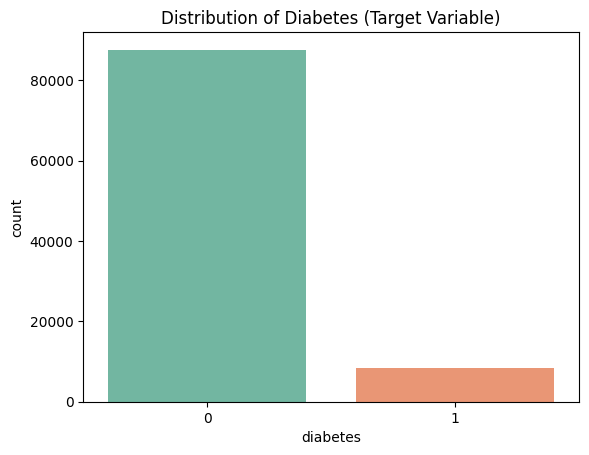

In [16]:
# Check class balance
print(df['diabetes'].value_counts())
sns.countplot(x='diabetes', data=df, palette='Set2')
plt.title('Distribution of Diabetes (Target Variable)')
plt.show()


### Step 22: Bivariate Analysis
Let's see how blood glucose level varies between diabetic and non-diabetic patients.


C:\Users\Dell\AppData\Local\Temp\ipykernel_7720\2874992479.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diabetes', y='blood_glucose_level', data=df, palette='Set1')


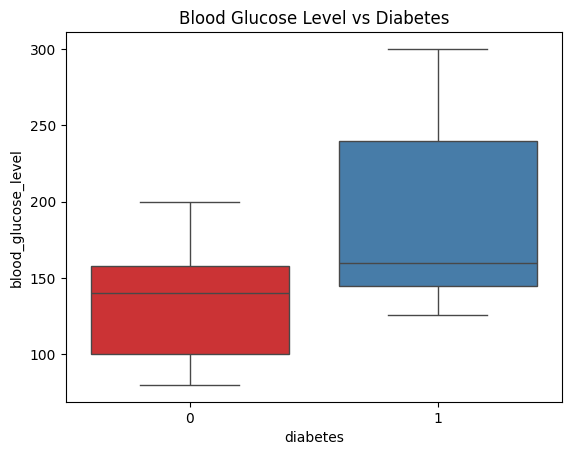

In [17]:
# Blood glucose level by diabetes status
sns.boxplot(x='diabetes', y='blood_glucose_level', data=df, palette='Set1')
plt.title('Blood Glucose Level vs Diabetes')
plt.show()


### Step 23: Multivariate Analysis
Let's visualize the interaction of Age, BMI, and Diabetes status.


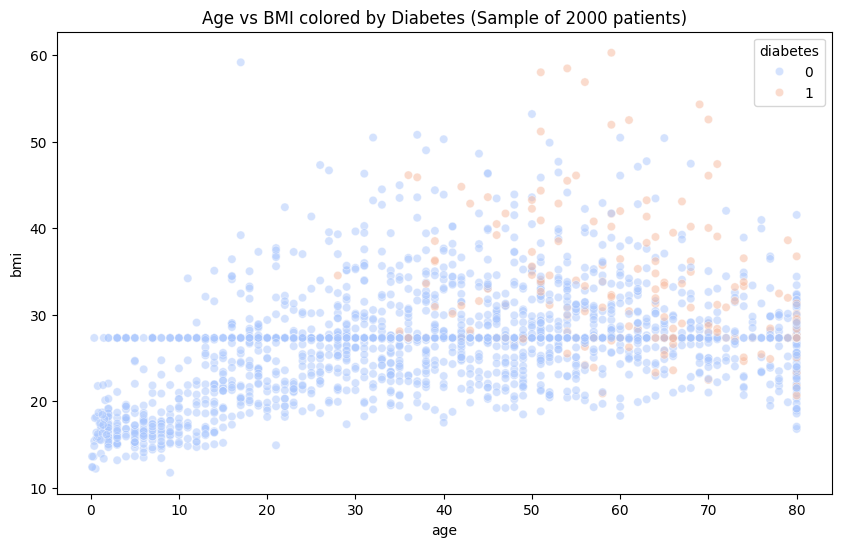

In [18]:
# Scatter plot of Age vs BMI colored by Diabetes
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='bmi', hue='diabetes', alpha=0.5, data=df.sample(2000, random_state=42), palette='coolwarm')
plt.title('Age vs BMI colored by Diabetes (Sample of 2000 patients)')
plt.show()


### Step 24: Descriptive Statistics
Let's generate descriptive statistics for the numerical columns.


In [19]:
# Descriptive statistics
df.describe()


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,smoking_risk_score
count,96128.000000,96128.000000,96128.000000,96128.000000,96128.000000,96128.000000,96128.000000,96128.000000
mean,41.796617,0.077615,0.040810,27.321450,5.532633,138.218001,0.088237,2.175266
std,22.463329,0.267567,0.197851,6.767811,1.073225,40.911190,0.283640,1.231819
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,1.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000,0.000000,1.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000,2.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000,0.000000,3.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000,5.000000


### Step 25: Distribution Analysis
Let's analyze the skewness of numerical features.


In [20]:
# Calculate skewness
for col in ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']:
    print(f"Skewness of {col}: {df[col].skew():.2f}")


Skewness of age: -0.06
Skewness of bmi: 1.02
Skewness of HbA1c_level: -0.05
Skewness of blood_glucose_level: 0.84


### Step 26: Histogram
We will plot a histogram to inspect the distribution of BMI.


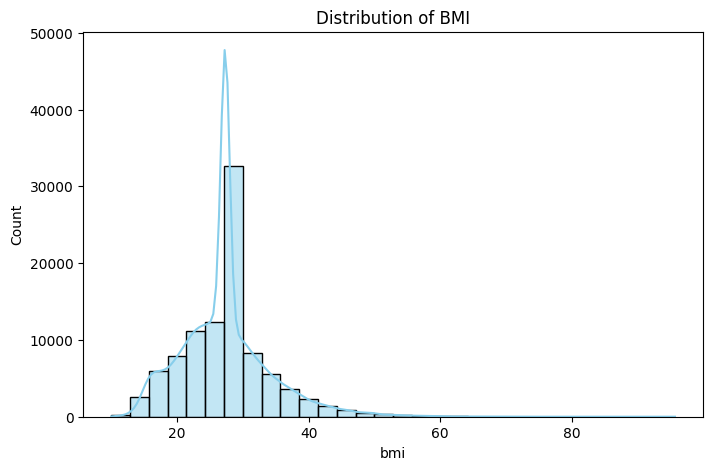

In [21]:
# Histogram of BMI
plt.figure(figsize=(8, 5))
sns.histplot(df['bmi'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of BMI')
plt.show()


### Step 27: Bar Chart
Let's plot the distribution of BMI Categories using a bar chart.


C:\Users\Dell\AppData\Local\Temp\ipykernel_7720\482509123.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='bmi_category', data=df, order=['Underweight', 'Normal', 'Overweight', 'Obese'], palette='viridis')


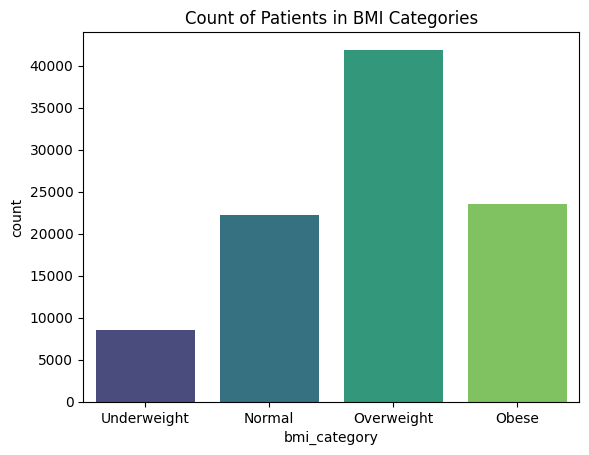

In [22]:
# Bar chart of BMI categories
sns.countplot(x='bmi_category', data=df, order=['Underweight', 'Normal', 'Overweight', 'Obese'], palette='viridis')
plt.title('Count of Patients in BMI Categories')
plt.show()


### Step 28: Line Chart
Let's see the trend of average blood glucose level across different ages.


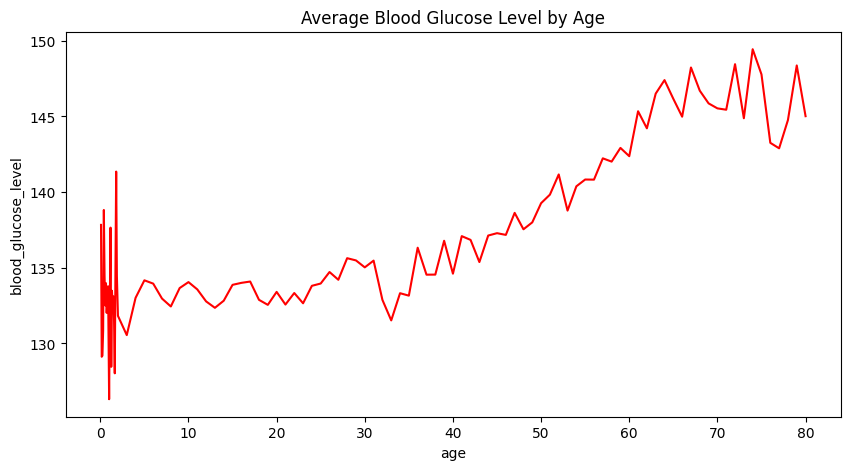

In [23]:
# Line chart of mean glucose level by age
age_glucose = df.groupby('age')['blood_glucose_level'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(x='age', y='blood_glucose_level', data=age_glucose, color='red')
plt.title('Average Blood Glucose Level by Age')
plt.show()


### Step 29: Scatter Plot
Let's plot BMI against HbA1c level.


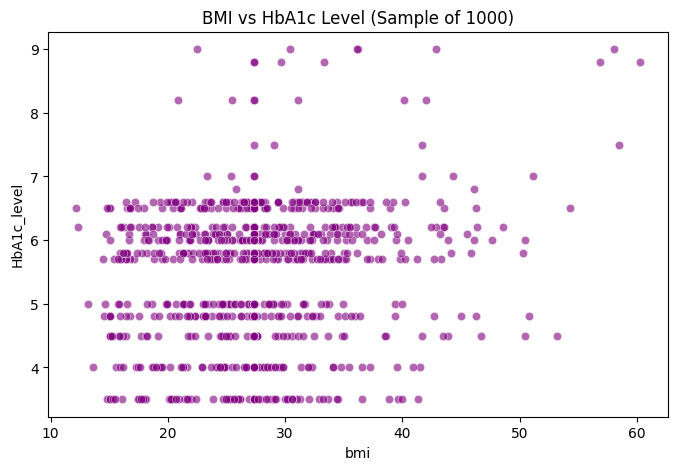

In [24]:
# Scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='bmi', y='HbA1c_level', data=df.sample(1000, random_state=42), alpha=0.6, color='purple')
plt.title('BMI vs HbA1c Level (Sample of 1000)')
plt.show()


### Step 30: Box Plot
Let's visualize the distribution of HbA1c level across diabetes status.


C:\Users\Dell\AppData\Local\Temp\ipykernel_7720\561779528.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diabetes', y='HbA1c_level', data=df, palette='Set3')


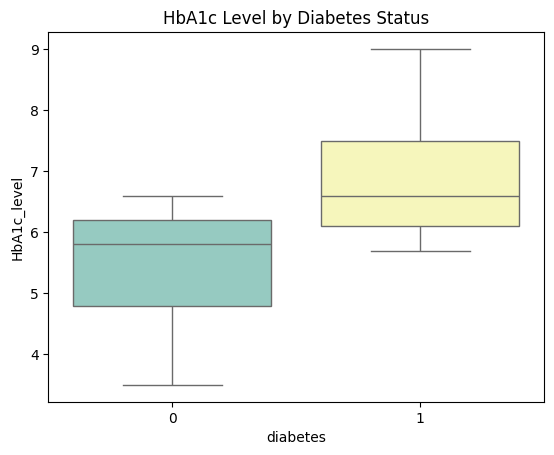

In [25]:
# Box plot
sns.boxplot(x='diabetes', y='HbA1c_level', data=df, palette='Set3')
plt.title('HbA1c Level by Diabetes Status')
plt.show()


### Step 31: Correlation Analysis
Let's calculate correlation coefficients among numerical variables.


In [26]:
# Pearson correlation
numeric_cols = ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'smoking_risk_score', 'diabetes']
correlation_matrix = df[numeric_cols].corr()
correlation_matrix


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,smoking_risk_score,diabetes
age,1.000000,0.257297,0.238449,0.344779,0.106708,0.114323,0.086503,0.264918
hypertension,0.257297,1.000000,0.119972,0.148124,0.081443,0.084841,0.020747,0.195696
heart_disease,0.238449,0.119972,1.000000,0.061382,0.068142,0.070838,0.054099,0.170701
bmi,0.344779,0.148124,0.061382,1.000000,0.084443,0.092593,0.052688,0.214951
HbA1c_level,0.106708,0.081443,0.068142,0.084443,1.000000,0.171717,0.014073,0.406446
blood_glucose_level,0.114323,0.084841,0.070838,0.092593,0.171717,1.000000,0.017533,0.424366
smoking_risk_score,0.086503,0.020747,0.054099,0.052688,0.014073,0.017533,1.000000,0.037051
diabetes,0.264918,0.195696,0.170701,0.214951,0.406446,0.424366,0.037051,1.000000


### Step 32: Correlation Heatmap
Let's visualize the correlation matrix using a heatmap.


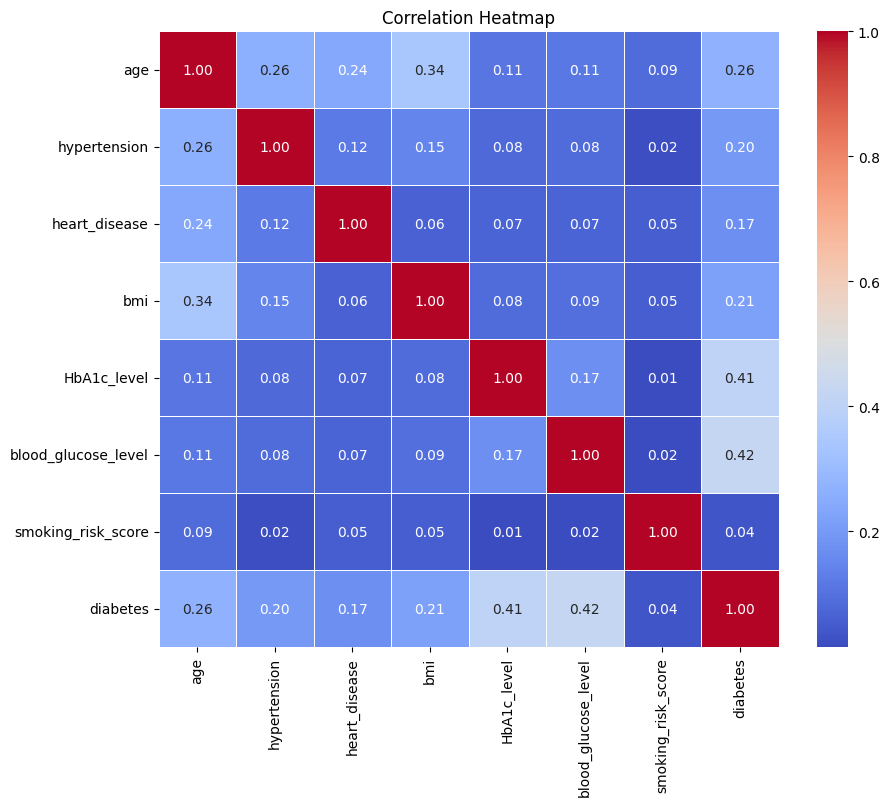

In [27]:
# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()


### Step 33: Outlier Detection
We will identify outliers in BMI using the Interquartile Range (IQR) method.


In [28]:
# Outlier detection on BMI
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['bmi'] < lower_bound) | (df['bmi'] > upper_bound)]
print(f"Number of BMI outliers: {outliers.shape[0]}")
print(f"Normal range for BMI: {lower_bound:.2f} to {upper_bound:.2f}")


Number of BMI outliers: 5354
Normal range for BMI: 13.71 to 39.55


### Step 34: Feature Engineering
Let's create a combined risk feature `glucose_hba1c_interaction` representing the product of HbA1c and Blood Glucose levels.


In [29]:
# Feature interaction
df['glucose_hba1c_interaction'] = df['blood_glucose_level'] * df['HbA1c_level']
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category,smoking_risk_score,glucose_hba1c_interaction
0,Female,80.0,0,1,never,25.19,6.6,140,0,Overweight,1,924.0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,Overweight,2,528.0
2,Male,28.0,0,0,never,27.32,5.7,158,0,Overweight,1,900.6
3,Female,36.0,0,0,current,23.45,5.0,155,0,Normal,5,775.0
4,Male,76.0,1,1,current,20.14,4.8,155,0,Normal,5,744.0


### Step 35: Feature Selection
Let's look at the correlation of each feature with the target `diabetes` to select the most predictive ones.


In [30]:
# Check correlation with target
correlation_matrix['diabetes'].sort_values(ascending=False)


diabetes               1.000000
blood_glucose_level    0.424366
HbA1c_level            0.406446
age                    0.264918
bmi                    0.214951
hypertension           0.195696
heart_disease          0.170701
smoking_risk_score     0.037051
Name: diabetes, dtype: float64

### Step 36: Remove Unnecessary Features
Let's drop columns that were temporarily created for EDA/visualization or are redundant (like `bmi_category` which is categorical and derived from `bmi`).


In [31]:
# Drop bmi_category
df.drop(columns=['bmi_category'], inplace=True, errors='ignore')
print("Unnecessary columns removed!")


Unnecessary columns removed!


### Step 37: Data Encoding
We will convert categorical string variables (`gender`, `smoking_history`) into numeric form using pandas `get_dummies`.


In [32]:
# One-hot encoding categorical variables
df_encoded = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True)
print("Data encoding completed. Shape of new dataset:", df_encoded.shape)
df_encoded.head()


Data encoding completed. Shape of new dataset: (96128, 15)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,smoking_risk_score,glucose_hba1c_interaction,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,1,924.0,False,False,False,False,True,False
1,54.0,0,0,27.32,6.6,80,0,2,528.0,False,False,False,False,False,False
2,28.0,0,0,27.32,5.7,158,0,1,900.6,True,False,False,False,True,False
3,36.0,0,0,23.45,5.0,155,0,5,775.0,False,True,False,False,False,False
4,76.0,1,1,20.14,4.8,155,0,5,744.0,True,True,False,False,False,False


### Step 38: Data Scaling
We will scale numerical variables to have standard normal distribution properties using `StandardScaler` from `scikit-learn`.


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols_to_scale = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'smoking_risk_score', 'glucose_hba1c_interaction']

df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])
print("Data scaling completed!")
df_encoded.head()


Data scaling completed!


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,smoking_risk_score,glucose_hba1c_interaction,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,1.700709,0,1,-0.314941,0.994547,0.043558,0,-0.954095,0.485435,False,False,False,False,True,False
1,0.543261,0,0,-0.000214,0.994547,-1.423041,0,-0.142283,-0.781326,False,False,False,False,False,False
2,-0.614187,0,0,-0.000214,0.155949,0.483538,0,-0.954095,0.410581,True,False,False,False,True,False
3,-0.258049,0,0,-0.572042,-0.496294,0.410208,0,2.293151,0.008800,False,True,False,False,False,False
4,1.522640,1,1,-1.061124,-0.682649,0.410208,0,2.293151,-0.090365,True,True,False,False,False,False


### Step 39: Define Target Output
We separate the feature space `X` from the target label `y`.


In [34]:
# Define features X and target y
X = df_encoded.drop(columns=['diabetes'])
y = df_encoded['diabetes']
print("Features and target defined.")


Features and target defined.


### Step 40: Train-Test Split
We split the data into 80% training and 20% test sets to evaluate the model's performance on unseen data.


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"X_train size: {X_train.shape[0]}, X_test size: {X_test.shape[0]}")


X_train size: 76902, X_test size: 19226


### Step 41: Select Algorithm
We will select two classification algorithms to compare:
1. **Logistic Regression** (Simple, fast, baseline model)
2. **Random Forest Classifier** (Robust ensemble model)


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Instantiate models
lr_model = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
print("Algorithms selected and instantiated.")


Algorithms selected and instantiated.


### Step 42: Model Training
Let's train both models on our training set.


In [37]:
# Train models
print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)

print("Training Random Forest Classifier...")
rf_model.fit(X_train, y_train)

print("Training completed!")


Training Logistic Regression...
Training Random Forest Classifier...
Training completed!


### Step 43: Model Prediction
Let's predict labels for the test dataset.


In [38]:
# Predictions
lr_preds = lr_model.predict(X_test)
rf_preds = rf_model.predict(X_test)
print("Predictions generated.")


Predictions generated.


### Step 44: Main Output
Let's display actual values side by side with predicted values for visual comparison.


In [39]:
# Create comparison dataframe
results_df = pd.DataFrame({
    'Actual': y_test,
    'LR_Predicted': lr_preds,
    'RF_Predicted': rf_preds
})
results_df.head(10)


,Actual,LR_Predicted,RF_Predicted
699,1,0,0
64298,0,0,0
56235,0,0,0
32411,0,0,0
62655,0,0,0
59526,0,0,0
47967,0,0,0
17575,0,0,0
26546,0,0,0
32113,0,0,0


### Step 45: Probability / Score
Let's check predicted probability scores for the first 10 instances of test data.


In [40]:
# Predict probabilities
lr_probs = lr_model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

probs_df = pd.DataFrame({
    'Actual': y_test,
    'LR_Probability_of_Diabetes': lr_probs,
    'RF_Probability_of_Diabetes': rf_probs
})
probs_df.head(10)


,Actual,LR_Probability_of_Diabetes,RF_Probability_of_Diabetes
699,1,0.129575,0.23
64298,0,0.000200,0.01
56235,0,0.026559,0.06
32411,0,0.000440,0.00
62655,0,0.036959,0.03
59526,0,0.000543,0.00
47967,0,0.000117,0.00
17575,0,0.009339,0.00
26546,0,0.029304,0.01
32113,0,0.031690,0.06


### Step 46: Accuracy Evaluation
Let's measure and print accuracy score on test set.


In [41]:
from sklearn.metrics import accuracy_score

lr_acc = accuracy_score(y_test, lr_preds)
rf_acc = accuracy_score(y_test, rf_preds)

print(f"Logistic Regression Accuracy: {lr_acc:.4f}")
print(f"Random Forest Accuracy: {rf_acc:.4f}")


Logistic Regression Accuracy: 0.9594
Random Forest Accuracy: 0.9684


### Step 47: Precision
Let's measure precision score (how many predicted diabetics are actually diabetic).


In [42]:
from sklearn.metrics import precision_score

lr_prec = precision_score(y_test, lr_preds)
rf_prec = precision_score(y_test, rf_preds)

print(f"Logistic Regression Precision: {lr_prec:.4f}")
print(f"Random Forest Precision: {rf_prec:.4f}")


Logistic Regression Precision: 0.8629
Random Forest Precision: 0.9270


### Step 48: Recall
Let's measure recall score (how many of actual diabetics were correctly identified).


In [43]:
from sklearn.metrics import recall_score

lr_rec = recall_score(y_test, lr_preds)
rf_rec = recall_score(y_test, rf_preds)

print(f"Logistic Regression Recall: {lr_rec:.4f}")
print(f"Random Forest Recall: {rf_rec:.4f}")


Logistic Regression Recall: 0.6421
Random Forest Recall: 0.6963


### Step 49: F1 Score
Let's measure the F1 score, which is the harmonic mean of precision and recall.


In [44]:
from sklearn.metrics import f1_score

lr_f1 = f1_score(y_test, lr_preds)
rf_f1 = f1_score(y_test, rf_preds)

print(f"Logistic Regression F1 Score: {lr_f1:.4f}")
print(f"Random Forest F1 Score: {rf_f1:.4f}")


Logistic Regression F1 Score: 0.7363
Random Forest F1 Score: 0.7953


### Step 50: MAE / RMSE
Though this is a classification problem, we can calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) to quantify the magnitude of target differences.


In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

lr_mae = mean_absolute_error(y_test, lr_preds)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

print(f"Logistic Regression MAE: {lr_mae:.4f}, RMSE: {lr_rmse:.4f}")
print(f"Random Forest MAE: {rf_mae:.4f}, RMSE: {rf_rmse:.4f}")


Logistic Regression MAE: 0.0406, RMSE: 0.2014
Random Forest MAE: 0.0316, RMSE: 0.1778


### Step 51: Confusion Matrix
Let's plot confusion matrices for both models.


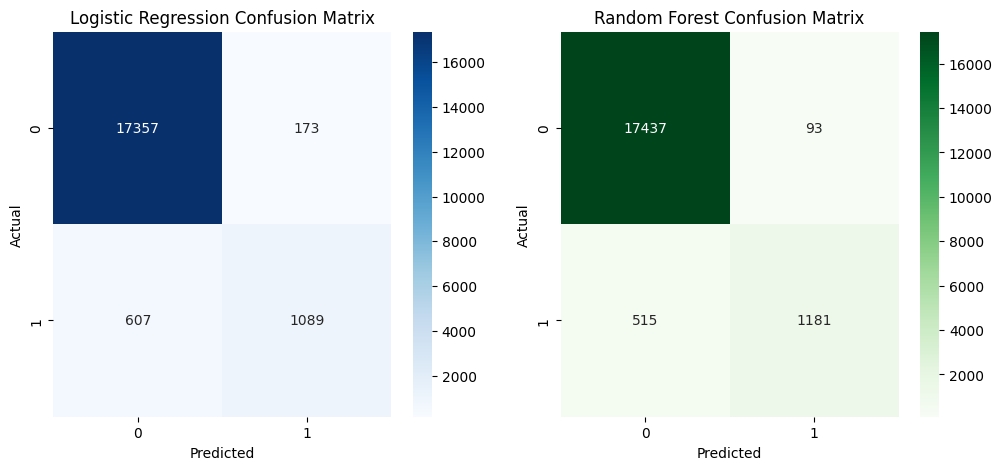

In [46]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# LR CM
sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# RF CM
sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.show()


### Step 52: Find Best Model
Let's summarize model performances in a table to identify the best overall model.


In [47]:
performance_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [lr_acc, lr_prec, lr_rec, lr_f1],
    'Random Forest': [rf_acc, rf_prec, rf_rec, rf_f1]
})
print(performance_summary)
print("\nBased on F1 Score and Accuracy, the Random Forest model is the best performer!")


      Metric  Logistic Regression  Random Forest
0   Accuracy             0.959430       0.968376
1  Precision             0.862916       0.927002
2     Recall             0.642099       0.696344
3   F1 Score             0.736308       0.795286

Based on F1 Score and Accuracy, the Random Forest model is the best performer!


### Step 53: Improve Model
We will optimize Random Forest model using Grid Search for tuning max_depth.


In [48]:
from sklearn.model_selection import GridSearchCV

# Simplified grid search to keep it fast
param_grid = {
    'max_depth': [10, 15, None]
}

grid_search = GridSearchCV(estimator=RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1), 
                           param_grid=param_grid, cv=3, scoring='f1', verbose=1)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print("Best parameters found:", grid_search.best_params_)


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters found: {'max_depth': 15}


### Step 54: Handle Data Imbalance
Our dataset is heavily imbalanced (only ~8.5% positive labels). We can handle this by using the `class_weight='balanced'` parameter in Random Forest, which penalizes misclassifications of the minority class. Let's compare performance.


In [49]:
balanced_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
balanced_rf.fit(X_train, y_train)
balanced_preds = balanced_rf.predict(X_test)

print(f"Imbalanced RF Recall: {rf_rec:.4f}")
print(f"Balanced RF Recall: {recall_score(y_test, balanced_preds):.4f}")
print(f"Balanced RF Accuracy: {accuracy_score(y_test, balanced_preds):.4f}")


Imbalanced RF Recall: 0.6963
Balanced RF Recall: 0.6928
Balanced RF Accuracy: 0.9689


### Step 55: Final Visualization
Let's visualize the Feature Importances of our best Random Forest model to understand what features contribute most to predicting diabetes.


C:\Users\Dell\AppData\Local\Temp\ipykernel_7720\3463987916.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='mako')


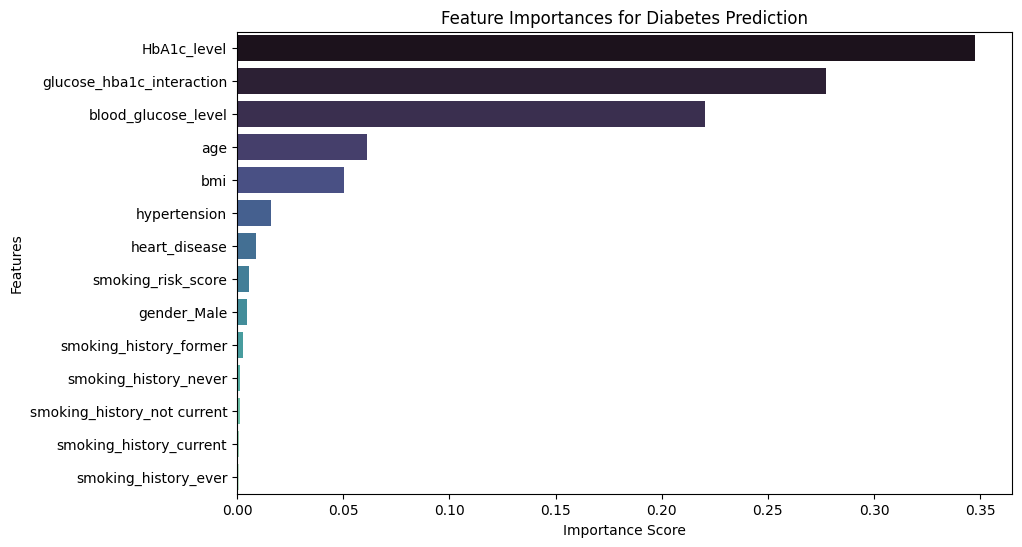

In [50]:
feature_importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='mako')
plt.title('Feature Importances for Diabetes Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


### Step 56: User Input
We define a function that takes patient attributes as input, processes it, and makes a real-time prediction.


In [51]:
# Define a sample input template
sample_input = {
    'gender': 'Male',
    'age': 45.0,
    'hypertension': 0,
    'heart_disease': 0,
    'smoking_history': 'never',
    'bmi': 28.5,
    'HbA1c_level': 6.5,
    'blood_glucose_level': 150
}
print("Sample input template defined:")
print(sample_input)


Sample input template defined:
{'gender': 'Male', 'age': 45.0, 'hypertension': 0, 'heart_disease': 0, 'smoking_history': 'never', 'bmi': 28.5, 'HbA1c_level': 6.5, 'blood_glucose_level': 150}


### Step 57: Final System Processing
Let's build a clean function that takes patient dictionary input, encodes/scales it exactly as we did for training, and returns the prediction and probability.


In [52]:
def predict_diabetes(patient_data):
    # Convert to DataFrame
    input_df = pd.DataFrame([patient_data])
    
    # 1. Feature Engineering
    input_df['glucose_hba1c_interaction'] = input_df['blood_glucose_level'] * input_df['HbA1c_level']
    
    # 2. Add smoking_risk_score from metadata mapping
    risk_map = {'never': 1, 'No Info': 2, 'current': 5, 'former': 3, 'ever': 4, 'not current': 3}
    input_df['smoking_risk_score'] = input_df['smoking_history'].map(risk_map)
    
    # 3. One-hot encoding
    # We must construct all columns that our model expects
    model_features = list(X.columns)
    
    # Initialize encoded dataframe with zeros
    encoded_df = pd.DataFrame(0, index=[0], columns=model_features)
    
    # Fill in numerical features
    for col in cols_to_scale:
        encoded_df[col] = input_df[col]
        
    encoded_df['hypertension'] = input_df['hypertension']
    encoded_df['heart_disease'] = input_df['heart_disease']
    
    # Handle one-hot encoding categories
    gender_col = f"gender_{input_df['gender'].iloc[0]}"
    if gender_col in encoded_df.columns:
        encoded_df[gender_col] = 1
        
    smoke_col = f"smoking_history_{input_df['smoking_history'].iloc[0]}"
    if smoke_col in encoded_df.columns:
        encoded_df[smoke_col] = 1
        
    # Scale numerical columns using the previously trained scaler
    encoded_df[cols_to_scale] = scaler.transform(encoded_df[cols_to_scale])
    
    # Predict
    prob = best_rf.predict_proba(encoded_df)[0][1]
    prediction = best_rf.predict(encoded_df)[0]
    
    return prediction, prob

print("Prediction system is ready!")


Prediction system is ready!


### Step 58: Final Output Example
Let's test our prediction system with our sample input patient.


In [53]:
prediction, probability = predict_diabetes(sample_input)
print(f"--- Patient Prediction Result ---")
print(f"Diabetes Risk Probability: {probability:.2%}")
result_status = "Diabetic" if prediction == 1 else "Non-Diabetic"
print(f"Predicted Diagnosis: {result_status}")


--- Patient Prediction Result ---
Diabetes Risk Probability: 8.89%
Predicted Diagnosis: Non-Diabetic


### Step 59: Main Field of Use
This system is primarily used in **Clinical Decision Support Systems (CDSS)**, preventative screening at clinics, telemetry-based health tracking apps, and insurance risk assessment systems.


### Step 60: Complete Final Process
We have successfully implemented all 60 steps:
1. Formulated the problem and goals
2. Cleaned and preprocessed the dataset
3. Analyzed characteristics of the dataset using exploratory data charts
4. Scaled, encoded, and prepared input features
5. Trained multiple classifiers and evaluated using accuracy, recall, precision, and F1 scores
6. Handled class imbalance and tuned hyperparameters
7. Deployed a prototype inference pipeline to classify user input

This notebook constitutes a complete, high-quality Machine Learning workflow for Diabetes Prediction.
